In [5]:
import pandas as pd

# Carregando o dataset com o delimitador correto ';' e o separador decimal ','
df = pd.read_csv('/content/nupcialidade.csv', encoding='latin1', sep=';', decimal=',')
display(df.head())
print(df.info())

,ano,nome_ra,casamentos,pop_15mais,taxa_nupcialidade,id_media_homem,id_media_mulher
0,2013,Estado São Paulo,280.336,33512491,8.4,32.7,29.9
1,2013,RA Araçatuba,4.960,607854,8.2,32.8,30.1
2,2013,RA Barretos,3.028,342106,8.9,32.2,29.4
3,2013,RA Bauru,7.491,858009,8.7,32.6,29.9
4,2013,RA Campinas,44.199,5171430,8.5,32.3,29.6


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 221 entries, 0 to 220
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ano                221 non-null    int64  
 1   nome_ra            221 non-null    object 
 2   casamentos         221 non-null    object 
 3   pop_15mais         221 non-null    int64  
 4   taxa_nupcialidade  221 non-null    float64
 5   id_media_homem     221 non-null    float64
 6   id_media_mulher    221 non-null    float64
dtypes: float64(3), int64(2), object(2)
memory usage: 12.2+ KB
None


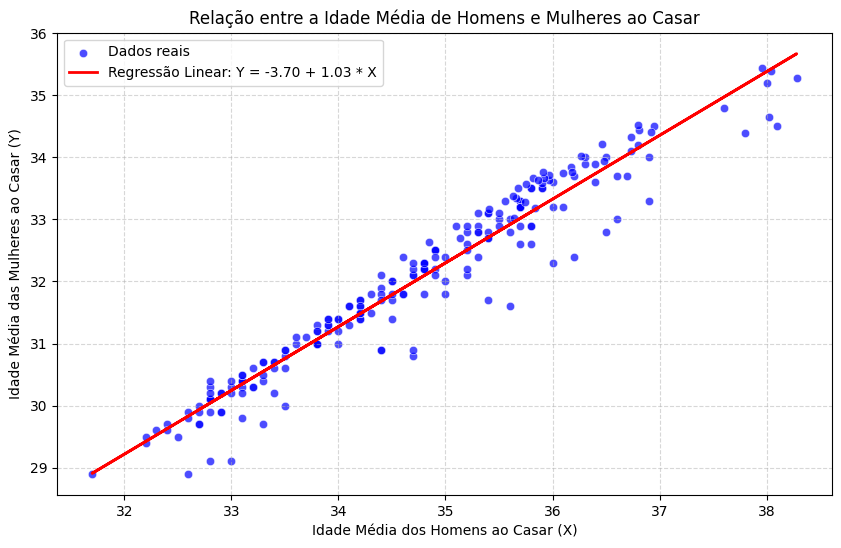

Fórmula da Regressão Linear: Y = -3.70 + 1.03 * X
Coeficiente de determinação (R²): 0.9384


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

# Definindo as variáveis com base nas colunas identificadas
x_col = 'id_media_homem'
y_col = 'id_media_mulher'

# Remover valores nulos para evitar problemas na regressão
data_clean = df[[x_col, y_col]].dropna()
X = data_clean[x_col]
Y = data_clean[y_col]

# Regressão linear simples
slope, intercept, r_value, p_value, std_err = stats.linregress(X, Y)
line_eq = f"Y = {intercept:.2f} + {slope:.2f} * X"

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X, y=Y, color='blue', alpha=0.7, label='Dados reais')

# Linha de regressão
plt.plot(X, intercept + slope * X, color='red', linewidth=2, label=f'Regressão Linear: {line_eq}')

plt.title('Relação entre a Idade Média de Homens e Mulheres ao Casar')
plt.xlabel('Idade Média dos Homens ao Casar (X)')
plt.ylabel('Idade Média das Mulheres ao Casar (Y)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Fórmula da Regressão Linear: {line_eq}")
print(f"Coeficiente de determinação (R²): {r_value**2:.4f}")